In [3]:
path = "coins_morfologi.bmp"
with open(path, "rb") as file:
    data = file.read()
if data[:2] != b"BM":
    raise ValueError("File bukan gambar BMP")
offset = int.from_bytes(data[10:14], "little")
width = int.from_bytes(data[18:22], "little", signed=True)
height = int.from_bytes(data[22:26], "little", signed=True)
bit_depth = int.from_bytes(data[28:30], "little")
compression = int.from_bytes(data[30:34], "little")
print("Lebar gambar:", width)
print("Tinggi gambar:", abs(height))
print("Bit depth:", bit_depth)
print("Offset piksel:", offset)
print("Kompresi:", compression)

Lebar gambar: 384
Tinggi gambar: 303
Bit depth: 24
Offset piksel: 54
Kompresi: 0


In [4]:
if width <= 0 or height <= 0:
    raise ValueError("Format gambar tidak didukung")
if bit_depth != 24 or compression != 0:
    raise ValueError("Format gambar tidak didukung")
image_height = abs(height)
row_size = ((width * 3 + 3) // 4) * 4
grayscale = []
for y in range(image_height):
    row = []
    if height > 0:
        file_row = image_height - 1 - y
    else:
        file_row = y
    for x in range(width):
        position = offset + file_row * row_size + x * 3
        b = data[position]
        g = data[position + 1]
        r = data[position + 2]
        gray = round(0.299 * r + 0.587 * g + 0.114 * b)
        row.append(gray)
    grayscale.append(row)
print("Jumlah baris:", len(grayscale))
print("Jumlah kolom:", len(grayscale[0]))
print("Contoh nilai grayscale:", grayscale[0][:10])

Jumlah baris: 303
Jumlah kolom: 384
Contoh nilai grayscale: [47, 123, 133, 129, 137, 132, 138, 135, 134, 133]


In [47]:
T = 135
binary = []
for row in grayscale:
    binary_row = []
    for pixel in row:
        if pixel > T:
            binary_row.append(255)
        else:
            binary_row.append(0)
    binary.append(binary_row)
print("Global Thresholding berhasil!")
print("Ukuran matriks:", len(binary), "x", len(binary[0]))
print("hasil:", binary)

Global Thresholding berhasil!
Ukuran matriks: 303 x 384
hasil: [[0, 0, 0, 0, 255, 0, 255, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 255, 255, 255, 255, 255, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 255, 255, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 255, 255, 0, 0, 255, 0, 255, 255, 0, 0, 0, 0, 255, 255, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

In [48]:
output_gambar = bytearray(data)
for y in range(image_height):
    if height > 0:
        file_row = image_height - 1 - y
    else:
        file_row = y
    for x in range(width):
        pixel = binary[y][x]
        position = offset + file_row * row_size + x * 3
        output_gambar[position] = pixel
        output_gambar[position + 1] = pixel
        output_gambar[position + 2] = pixel
with open("coins_morfologi_binary.bmp", "wb") as file:
    file.write(output_gambar)

In [60]:
def dilation(image):
    rows = len(image)
    columns = len(image[0])
    dilation = []
    for y in range(rows):
        new_row = []
        for x in range(columns):
            piksel = 0
            for ky in range(-1, 2):
                for kx in range(-1, 2):
                    ny = y + ky
                    nx = x + kx
                    if 0 <= ny < rows and 0 <= nx < columns:
                        if image[ny][nx] == 255:
                            piksel = 255
            new_row.append(piksel)
        dilation.append(new_row)
    return dilation

In [61]:
def erosion(image):
    rows = len(image)
    columns = len(image[0])
    erosion = []
    for y in range(rows):
        new_row = []
        for x in range(columns):
            piksel = 255
            for ky in range(-1, 2):
                for kx in range(-1, 2):
                    ny = y + ky
                    nx = x + kx
                    if 0 <= ny < rows and 0 <= nx < columns:
                        if image[ny][nx] == 0:
                            piksel = 0
                    else:
                        piksel = 0
            new_row.append(piksel)
        erosion.append(new_row)
    return erosion

In [63]:
dilation_result = dilation(binary)
erosion_result = erosion(binary)
opening = dilation(erosion(binary))
closing = erosion(dilation(binary))
opening_closing = erosion(dilation(opening))

In [64]:
output_gambar = bytearray(data)
for y in range(image_height):
    if height > 0:
        file_row = image_height - 1 - y
    else:
        file_row = y
    for x in range(width):
        pixel = dilation_result[y][x]
        position = offset + file_row * row_size + x * 3
        output_gambar[position] = pixel
        output_gambar[position + 1] = pixel
        output_gambar[position + 2] = pixel
with open("coins_morfologi_final.bmp", "wb") as file:
    file.write(output_gambar)

In [65]:
output_gambar = bytearray(data)
for y in range(image_height):
    if height > 0:
        file_row = image_height - 1 - y
    else:
        file_row = y
    for x in range(width):
        pixel = erosion_result[y][x]
        position = offset + file_row * row_size + x * 3
        output_gambar[position] = pixel
        output_gambar[position + 1] = pixel
        output_gambar[position + 2] = pixel
with open("coins_morfologi_final.bmp", "wb") as file:
    file.write(output_gambar)

In [66]:
output_gambar = bytearray(data)
for y in range(image_height):
    if height > 0:
        file_row = image_height - 1 - y
    else:
        file_row = y
    for x in range(width):
        pixel = closing[y][x]
        position = offset + file_row * row_size + x * 3
        output_gambar[position] = pixel
        output_gambar[position + 1] = pixel
        output_gambar[position + 2] = pixel
with open("coins_morfologi_final.bmp", "wb") as file:
    file.write(output_gambar)

In [67]:
for y in range(image_height):
    if height > 0:
        file_row = image_height - 1 - y
    else:
        file_row = y
    for x in range(width):
        pixel = opening[y][x]
        position = offset + file_row * row_size + x * 3
        output_gambar[position] = pixel
        output_gambar[position + 1] = pixel
        output_gambar[position + 2] = pixel
with open("coins_morfologi_final.bmp", "wb") as file:
    file.write(output_gambar)

In [68]:
for y in range(image_height):
    if height > 0:
        file_row = image_height - 1 - y
    else:
        file_row = y
    for x in range(width):
        pixel = opening_closing[y][x]
        position = offset + file_row * row_size + x * 3
        output_gambar[position] = pixel
        output_gambar[position + 1] = pixel
        output_gambar[position + 2] = pixel
with open("coins_morfologi_final.bmp", "wb") as file:
    file.write(output_gambar)

Global Thresholding


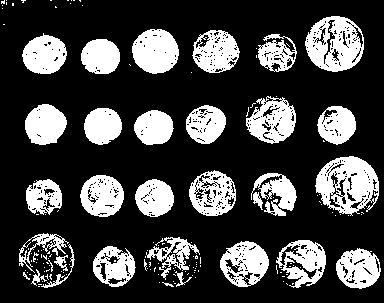

Dilation


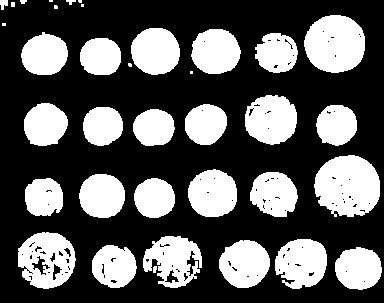

Erosion


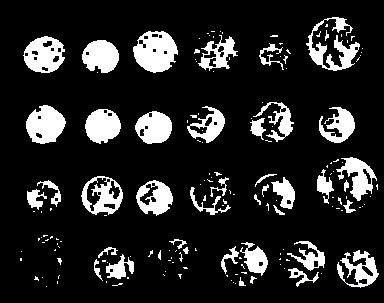

Closing


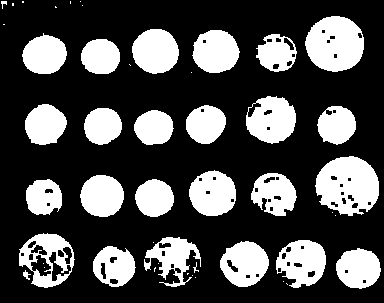

Opening


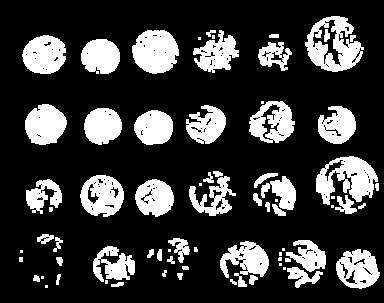

Opening + Closing


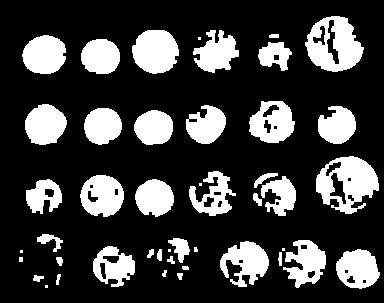

In [69]:
hasil = [
    ("Global Thresholding", binary),("Dilation", dilation_result),("Erosion", erosion_result),("Closing", closing),("Opening", opening),("Opening + Closing", opening_closing)
]
for nama, matriks in hasil:
    tinggi = len(matriks)
    lebar = len(matriks[0])
    svg = [
        f'<svg xmlns="http://www.w3.org/2000/svg" '
        f'width="{lebar}" height="{tinggi}" '
        f'viewBox="0 0 {lebar} {tinggi}">',
        f'<rect width="{lebar}" height="{tinggi}" fill="black"/>'
    ]
    for y in range(tinggi):
        awal = None
        for x in range(lebar + 1):
            putih = x < lebar and matriks[y][x] == 255
            if putih and awal is None:
                awal = x
            elif not putih and awal is not None:
                svg.append(
                    f'<rect x="{awal}" y="{y}" '
                    f'width="{x-awal}" height="1" fill="white"/>'
                )
                awal = None
    svg.append("</svg>")
    print(nama)
    display({"image/svg+xml": "".join(svg)}, raw=True)
